### 📈 Avaliação de Desempenho e Métricas

Para comparar o desempenho dos diferentes otimizadores e configurações do `MLPClassifier`, utilizamos uma metodologia de avaliação robusta:

1.  **Divisão de Dados:** Cada conjunto de dados (Iris, Digits, Circles, Moons) foi dividido em 80% para **treinamento** e 20% para **teste** usando `train_test_split`. Essa divisão é feita de forma estratificada (`stratify=y`) para garantir que a proporção de classes seja mantida em ambos os conjuntos, e com um `random_state` fixo para garantir a reprodutibilidade dos resultados.

2.  **Pré-processamento:** Antes de treinar os modelos, os dados foram escalados usando `MinMaxScaler`. Este processo garante que todas as características (features) estejam na mesma faixa (entre 0 e 1), o que é crucial para a convergência e desempenho de redes neurais. O `MinMaxScaler` é ajustado apenas nos dados de treinamento e depois aplicado tanto aos dados de treinamento quanto aos de teste para evitar vazamento de informações.

3.  **Treinamento do Modelo:** Cada `MLPClassifier` é treinado exclusivamente com os dados de **treinamento escalados**.

4.  **Métricas de Avaliação:**
    *   **Curva de Perda (Loss Curve):** Visualizamos a `loss_curve_` de cada modelo, que mostra como a função de custo diminui ao longo das iterações de treinamento. Isso nos ajuda a entender a dinâmica de aprendizado de cada otimizador.
    *   **Acurácia de Treinamento (Training Score):** Mede o quão bem o modelo se ajustou aos dados que ele "viu" durante o treinamento.
    *   **Acurácia de Teste (Test Score):** Esta é a métrica mais importante! Ela avalia a capacidade do modelo de **generalizar** para dados **não vistos**. Uma alta acurácia de teste indica um modelo robusto e que não sofreu de *overfitting*.

Ao comparar essas métricas para cada otimizador e dataset, podemos identificar qual configuração oferece o melhor equilíbrio entre velocidade de convergência, capacidade de aprendizado e generalização.

O código tem um objetivo bem definido: comparar visualmente as curvas de perda de diferentes configurações do MLPClassifier. É uma maneira de de visualizar e comparar o desempenho de diferentes otimizadores e agendamentos de taxa de aprendizado (learning_rate) para o MLPClassifier em vários conjuntos de dados. Ele demonstra claramente como a escolha desses hiperparâmetros afeta a curva de perda durante o treinamento.  

O uso de random_state=0 no MLPClassifier garante que os resultados sejam reproduzíveis, o que é crucial para experimentos.  

A aplicação do MinMaxScaler é uma boa prática para redes neurais, pois ajuda na convergência e evita que features com escalas maiores dominem o processo de aprendizado.  

Ignorar ConvergenceWarning é apropriado para este tipo de demonstração, onde o foco é a comparação das curvas de perda e nem todos os modelos podem convergir dentro do max_iter definido.  

O uso de matplotlib para plotar as curvas de perda é direto e eficaz, permitindo uma comparação visual rápida entre as diferentes configurações.  

Testar múltiplos datasets (em iris, digits, circles e moons) mostra como os diferentes otimizadores se comportam em problemas de complexidade e características variadas.  

A função plot_on_dataset encapsula bem a lógica de treinamento e plotagem para cada conjunto de dados.  


learning on dataset iris
Dataset: iris, training: constant learning-rate
Dataset: iris, Config: constant learning-rate - Training set score: 0.9750
Dataset: iris, Config: constant learning-rate - Training set loss: 0.1799
Dataset: iris, Config: constant learning-rate - Test set score: 0.9333
  Confusion Matrix for constant learning-rate:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]
  Classification Report for constant learning-rate:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.90      0.90      0.90        10
           2       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

  Training time: 0.10 seconds
Dataset: iris, training: constant with momentum
Dataset: iris, Config: constant with momentum - Training set score: 0.9833
Dataset: iris, Config: constant with

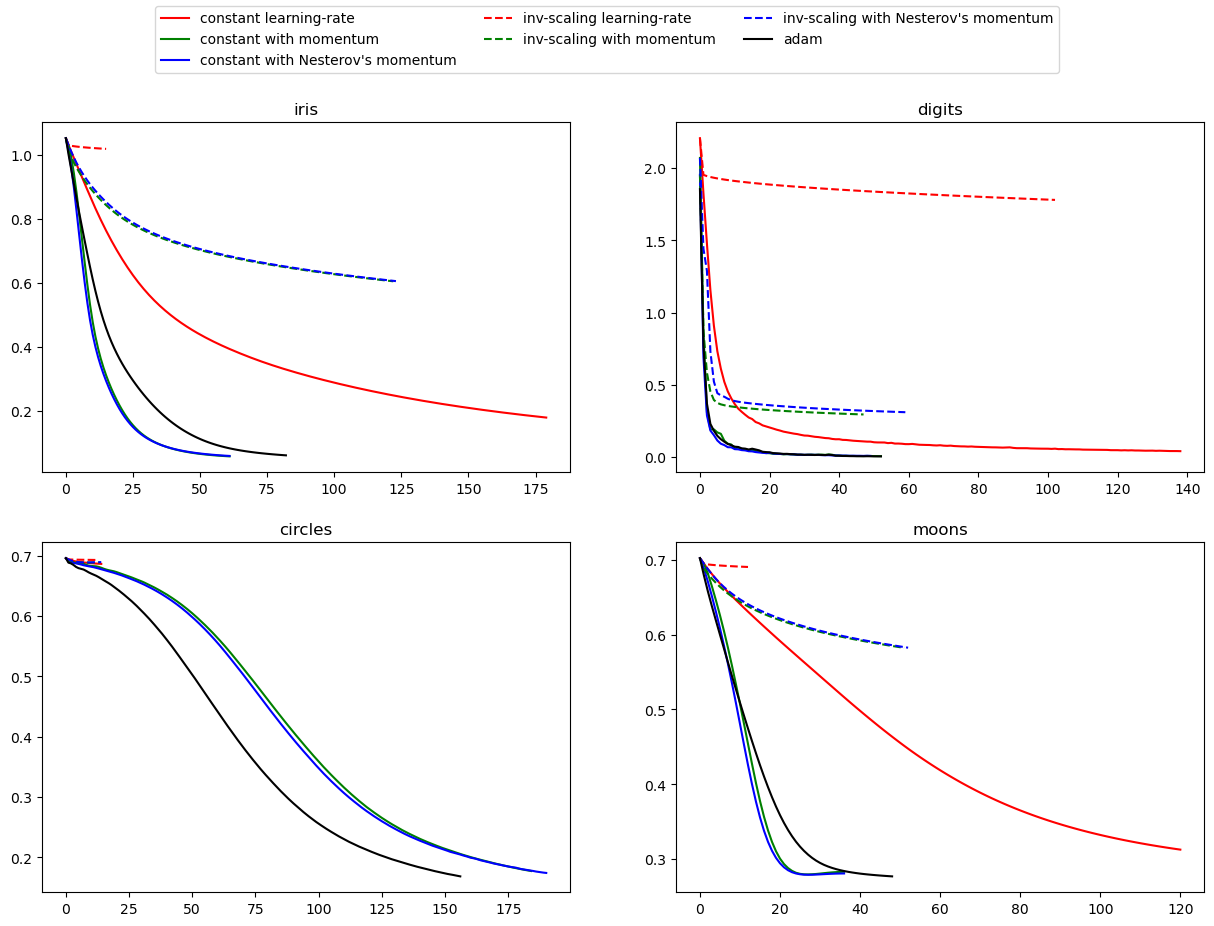

In [10]:
import warnings

import matplotlib.pyplot as plt

from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn import datasets
from sklearn.exceptions import ConvergenceWarning

from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
import time


params = [
    {
        "solver": "sgd",
        "learning_rate": "constant",
        "momentum": 0,
        "tol": 1e-3,
        "learning_rate_init": 0.2,
    },
    {
        "solver": "sgd",
        "learning_rate": "constant",
        "momentum": 0.9,
        "nesterovs_momentum": False,
        "tol": 1e-3,
        "learning_rate_init": 0.2,
    },
    {
        "solver": "sgd",
        "learning_rate": "constant",
        "momentum": 0.9,
        "nesterovs_momentum": True,
        "tol": 1e-3,
        "learning_rate_init": 0.2,
    },
    {
        "solver": "sgd",
        "learning_rate": "invscaling",
        "momentum": 0,
        "learning_rate_init": 0.2,
        "tol": 1e-3,
    },
    {
        "solver": "sgd",
        "learning_rate": "invscaling",
        "momentum": 0.9,
        "nesterovs_momentum": True,
        "learning_rate_init": 0.2,
        "tol": 1e-3,
    },
    {
        "solver": "sgd",
        "learning_rate": "invscaling",
        "momentum": 0.9,
        "nesterovs_momentum": False,
        "learning_rate_init": 0.2,
        "tol": 1e-3,
    },
    {"solver": "adam", "learning_rate_init": 0.01, "tol": 1e-3,},
]

labels = [
    "constant learning-rate",
    "constant with momentum",
    "constant with Nesterov's momentum",
    "inv-scaling learning-rate",
    "inv-scaling with momentum",
    "inv-scaling with Nesterov's momentum",
    "adam",
]

plot_args = [
    {"c": "red", "linestyle": "-"},
    {"c": "green", "linestyle": "-"},
    {"c": "blue", "linestyle": "-"},
    {"c": "red", "linestyle": "--"},
    {"c": "green", "linestyle": "--"},
    {"c": "blue", "linestyle": "--"},
    {"c": "black", "linestyle": "-"},
]


def plot_on_dataset(X, y, ax, name):

    """
    Treina e plota as curvas de perda de MLPClassifiers com diferentes
    configurações de otimizador em um dado dataset.

    Args:
        X (array-like): Features do dataset.
        y (array-like): Rótulos do dataset.
        ax (matplotlib.axes.Axes): Eixo onde os plots serão desenhados.
        name (str): Nome do dataset para o título do plot.
    """

    print("\nlearning on dataset %s" % name)
    ax.set_title(name)


    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    scaler = MinMaxScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)


    mlps = []
    if name == "digits":
        max_iter = 2000
    else:
        max_iter = 5000

    for label, param in zip(labels, params):
        print(f"Dataset: {name}, training: {label}")
        mlp = MLPClassifier(random_state=0, max_iter=max_iter, **param)

        with warnings.catch_warnings():
            warnings.filterwarnings(
                "ignore", category=ConvergenceWarning, module="sklearn"
            )
            mlp.fit(X_train_scaled, y_train) # Treinar com dados de treino escalados

        mlps.append(mlp)
        print(f"Dataset: {name}, Config: {label} - Training set score: {mlp.score(X_train_scaled, y_train):.4f}")
        print(f"Dataset: {name}, Config: {label} - Training set loss: {mlp.loss_:.4f}")
        print(f"Dataset: {name}, Config: {label} - Test set score: {mlp.score(X_test_scaled, y_test):.4f}")

        y_pred = mlp.predict(X_test_scaled)
        cm = confusion_matrix(y_test, y_pred)
        print(f"  Confusion Matrix for {label}:\n{cm}")

        y_pred = mlp.predict(X_test_scaled)
        report = classification_report(y_test, y_pred, zero_division=0) # zero_division=0 para evitar warnings
        print(f"  Classification Report for {label}:\n{report}")

        start_time = time.time()
        mlp.fit(X_train_scaled, y_train)
        end_time = time.time()
        print(f"  Training time: {end_time - start_time:.2f} seconds")

    
    for mlp, label, args in zip(mlps, labels, plot_args):
        ax.plot(mlp.loss_curve_, label=label, **args)


fig, axes = plt.subplots(2, 2, figsize=(15, 10))
iris = datasets.load_iris()
X_digits, y_digits = datasets.load_digits(return_X_y=True)
data_sets = [
    (iris.data, iris.target),
    (X_digits, y_digits),
    datasets.make_circles(noise=0.2, factor=0.5, random_state=1),
    datasets.make_moons(noise=0.3, random_state=0),
]

for ax, data, name in zip(
    axes.ravel(), data_sets, ["iris", "digits", "circles", "moons"]
):
    plot_on_dataset(*data, ax=ax, name=name)

fig.legend(ax.get_lines(), labels, ncol=3, loc="upper center")
plt.show()